---
title: "Radiation — Level 2"
short_title: "09 Radiation"
numbering:
  heading_2: true
  equation: true
---

# Radiation

:::{seealso} Math for this topic
- [E-M3: Waves and Fourier transforms](../math/03-waves-fourier-transforms.ipynb)
- [M1: Vectors and ODEs](../../level2-book/math/01-vectors-odes.ipynb)
- [M2: Coordinates, integrals and the delta function](../../level2-book/math/02-coordinates-integrals-delta.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | — (not covered in Tipler & Mosca) | Start at Level 2 |
| **2** | **Griffiths, ch. 10–11** | **Retarded potentials, dipole radiation, the Larmor formula** |
| 3 | Jackson, ch. 9 and 14 | Multipole radiation, Liénard–Wiechert potentials, synchrotron radiation |

The new skill at this level: solving for fields of time-dependent sources with retarded potentials, and finding the part that carries energy to infinity

Math for this topic: E-M3 (waves, retarded time), mechanics M1 (Taylor series) and M2 (spherical coordinates).
:::

Workbook example ladder: antenna power → electric dipole radiation pattern → radiation from a relativistic charge in circular motion. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad, dblquad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
eps0 = 8.854e-12          # F/m
mu0 = 4e-7 * np.pi        # H/m (to 10 significant figures)
c = 2.998e8               # m/s
k_e = 1 / (4 * np.pi * eps0)

## Potentials for Time-Dependent Fields

$\nabla\cdot\vec{B} = 0$ still allows $\vec{B} = \nabla\times\vec{A}$. Faraday's law then says $\nabla\times(\vec{E} + \partial\vec{A}/\partial t) = \vec{0}$, so that combination is a gradient:

$$
\vec{E} = -\nabla V - \frac{\partial\vec{A}}{\partial t}, \qquad \vec{B} = \nabla\times\vec{A} .
$$ (eq-potentials-dynamic)

Two Maxwell equations are now automatic, and the other two become equations for $V$ and $\vec{A}$.

### Gauge freedom

The transformation $\vec{A}\to\vec{A} + \nabla\lambda$, $V\to V - \partial\lambda/\partial t$ leaves $\vec{E}$ and $\vec{B}$ unchanged for any function $\lambda(\vec{r}, t)$. Use the freedom to simplify. The **Lorenz gauge**, $\nabla\cdot\vec{A} = -\mu_0\epsilon_0\,\partial V/\partial t$, turns the remaining Maxwell equations into four uncoupled inhomogeneous wave equations:

$$
\nabla^2V - \frac{1}{c^2}\frac{\partial^2V}{\partial t^2} = -\frac{\rho}{\epsilon_0}, \qquad
\nabla^2\vec{A} - \frac{1}{c^2}\frac{\partial^2\vec{A}}{\partial t^2} = -\mu_0\vec{J} .
$$

(The Lorenz gauge also treats $V$ and $\vec{A}$ symmetrically, which makes it the natural choice in relativity, topic 10.)

## Retarded Potentials

In statics the solutions were $V = \frac{1}{4\pi\epsilon_0}\int\rho/\mathscr{r}\,d\tau'$ and its partner for $\vec{A}$. For time-dependent sources, news travels at $c$, so the field at $\vec{r}$ at time $t$ depends on what each source element was doing at the earlier **retarded time**

$$
t_r = t - \frac{\mathscr{r}}{c} .
$$

The solutions of the wave equations are the **retarded potentials**:

$$
V(\vec{r}, t) = \frac{1}{4\pi\epsilon_0}\int\frac{\rho(\vec{r}', t_r)}{\mathscr{r}}\,d\tau', \qquad
\vec{A}(\vec{r}, t) = \frac{\mu_0}{4\pi}\int\frac{\vec{J}(\vec{r}', t_r)}{\mathscr{r}}\,d\tau' .
$$ (eq-retarded)

They look like the static formulas with the sources evaluated late, but the fields obtained from them are **not** just retarded Coulomb and Biot–Savart fields: differentiating $t_r$ with respect to position produces extra terms, and those terms are the radiation.

For a single point charge, the integrals give the **Liénard–Wiechert potentials**, whose fields contain a piece that falls as $1/\mathscr{r}$ and is proportional to the charge's **acceleration**. That piece is radiation.

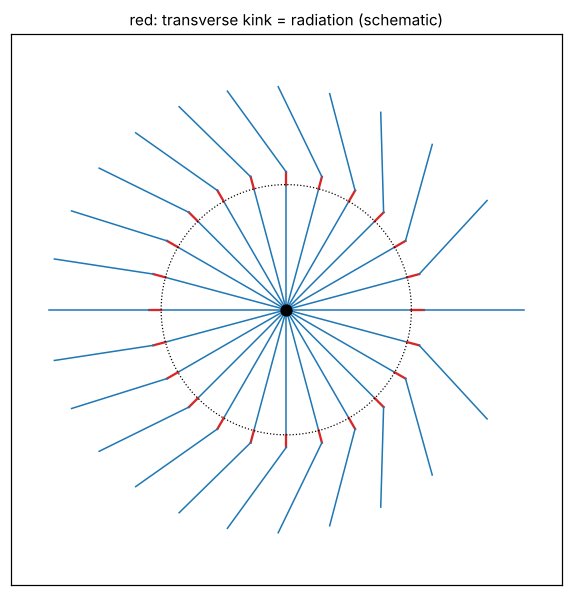

In [2]:
#| label: fig-retarded
#| caption: Field lines of a charge that moved at constant velocity, stopped abruptly, and is now at rest (snapshot at time T after the stop, speed 0.8c). Inside radius cT the field is the Coulomb field of the charge at rest; outside it, it still points to where the charge would have been. The kink joining them, a thin shell moving outward at c, is the radiation pulse.
c_ = 1.0; v = 0.8; T = 2.5
fig, ax = plt.subplots(figsize=(6.5, 6.5))
angles = np.linspace(0, 2 * np.pi, 24, endpoint=False)
for th in angles:
    # inside cT: radial from the stopped charge at origin
    r_in = np.linspace(0.05, c_ * T, 20)
    xi, yi = r_in * np.cos(th), r_in * np.sin(th)
    # outside c(T + dt): radial from the extrapolated position x = vT (direction th' given by relativistic compression is ignored; drawn schematically)
    p_out = np.array([v * T, 0.0])
    xo0, yo0 = c_ * (T + 0.25) * np.cos(th), c_ * (T + 0.25) * np.sin(th)
    d = np.array([xo0, yo0]) - p_out; d /= np.linalg.norm(d)
    start = np.array([xo0, yo0]); end = start + d * 2.0
    ax.plot(xi, yi, color="tab:blue", lw=1)
    ax.plot([xi[-1], start[0]], [yi[-1], start[1]], color="tab:red", lw=1.5)
    ax.plot([start[0], end[0]], [start[1], end[1]], color="tab:blue", lw=1)
ax.plot(0, 0, "ko", ms=7)
tt = np.linspace(0, 2 * np.pi, 200)
ax.plot(c_ * T * np.cos(tt), c_ * T * np.sin(tt), "k:", lw=0.8)
ax.set_aspect("equal"); ax.set_xlim(-5.5, 5.5); ax.set_ylim(-5.5, 5.5); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("red: transverse kink = radiation (schematic)", fontsize=10)
plt.show()

## Electric Dipole Radiation

Take a dipole oscillating along $z$, $\vec{p}(t) = p_0\cos(\omega t)\,\hat{z}$, of size $d$. Assume three separations of scale:

$$
d\ll\lambda\ll r ,
$$

a small source, observed far away (the **radiation zone**). Expanding the retarded potentials in $d/r$ and $d/\lambda$ (mechanics M1, Taylor series) and keeping only terms that fall as $1/r$ gives the radiation fields:

$$
\vec{E} = -\frac{\mu_0p_0\omega^2}{4\pi}\frac{\sin\theta}{r}\cos\left[\omega\left(t - \frac rc\right)\right]\hat{\theta}, \qquad
\vec{B} = \frac1c\,\hat{r}\times\vec{E} .
$$

These are spherical waves (E-M3) with the transverse $\vec{E}$, $\vec{B}$, $\hat{r}$ triad of a plane wave, but with amplitude $\propto\sin\theta/r$. The time-averaged Poynting vector and total power are

$$
\langle\vec{S}\rangle = \frac{\mu_0p_0^2\omega^4}{32\pi^2c}\frac{\sin^2\theta}{r^2}\,\hat{r}, \qquad
\langle P\rangle = \frac{\mu_0p_0^2\omega^4}{12\pi c} .
$$ (eq-dipole-power)

Three features matter:

- $S\propto1/r^2$, so the power through any large sphere is the same: energy escapes to infinity. Static fields fall faster and carry nothing away.
- No radiation along the dipole axis; the pattern is a donut, $\propto\sin^2\theta$.
- $P\propto\omega^4$. Air molecules are tiny dipoles driven by sunlight, so they scatter blue light ($\lambda\approx450$ nm) about $(700/450)^4\approx6$ times more strongly than red. That is why the sky is blue and sunsets are red.

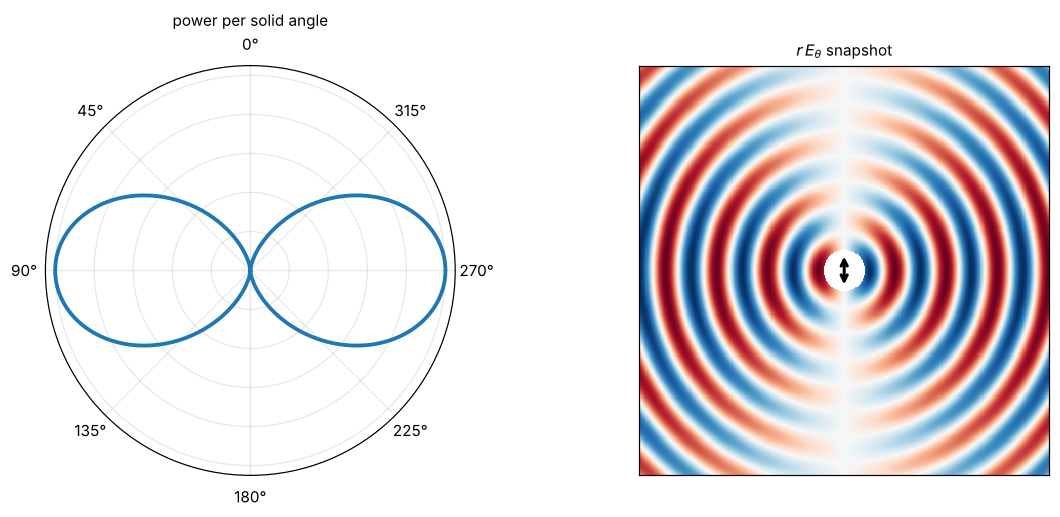

In [3]:
#| label: fig-dipole-pattern
#| caption: Left, the sin²θ radiation pattern of an oscillating dipole (dipole along the vertical axis). Right, a snapshot of the radiated field r·E_θ in a plane containing the dipole, showing outgoing wavefronts with no radiation along the axis.
th = np.linspace(0, 2 * np.pi, 400)
fig = plt.figure(figsize=(11, 4.8))
ax = fig.add_subplot(1, 2, 1, projection="polar")
ax.plot(th, np.sin(th)**2, lw=2.5)
ax.set_theta_zero_location("N"); ax.set_yticklabels([]); ax.set_title("power per solid angle", fontsize=10)
ax2 = fig.add_subplot(1, 2, 2)
x = np.linspace(-6, 6, 400); z = np.linspace(-6, 6, 400)
X, Z = np.meshgrid(x, z)
r = np.hypot(X, Z) + 1e-9
sinth = np.abs(X) / r
k = 2 * np.pi / 1.5
field = sinth * np.cos(k * r) * np.sign(X)
field[r < 0.6] = np.nan
ax2.pcolormesh(X, Z, field, cmap="RdBu_r", shading="auto", vmin=-1, vmax=1)
ax2.annotate("", xy=(0, 0.5), xytext=(0, -0.5), arrowprops=dict(arrowstyle="<->", lw=2))
ax2.set_aspect("equal"); ax2.set_xticks([]); ax2.set_yticks([]); ax2.set_title(r"$r\,E_\theta$ snapshot", fontsize=10)
plt.tight_layout(); plt.show()

In [4]:
# Total power: integrate the angular distribution over a sphere
th, ph, r = sp.symbols("theta phi r", positive=True)
mu0_, p0, w, c_s = sp.symbols("mu_0 p_0 omega c", positive=True)
S = mu0_ * p0**2 * w**4 / (32 * sp.pi**2 * c_s) * sp.sin(th)**2 / r**2
P = sp.integrate(S * r**2 * sp.sin(th), (th, 0, sp.pi), (ph, 0, 2 * sp.pi))
display(Math(r"\langle P\rangle = " + sp.latex(sp.simplify(P))))
print("blue/red scattering ratio (450 nm vs 700 nm):", round((700 / 450)**4, 2))

<IPython.core.display.Math object>

blue/red scattering ratio (450 nm vs 700 nm): 5.86


### Antennas and radiation resistance

A short antenna of length $d\ll\lambda$ carrying current $I_0\cos\omega t$ has an oscillating dipole moment with $p_0\omega = I_0d$. By {eq}`eq-dipole-power` it radiates $\langle P\rangle = \frac{\mu_0I_0^2d^2\omega^2}{12\pi c}$. Writing this as $\tfrac12I_0^2R_{\text{rad}}$ defines the **radiation resistance**, the resistance that would dissipate the same power:

$$
R_{\text{rad}} = \frac{2\pi}{3}\sqrt{\frac{\mu_0}{\epsilon_0}}\left(\frac d\lambda\right)^2\approx790\left(\frac d\lambda\right)^2\ \Omega .
$$

A short antenna is a poor radiator: at $d = \lambda/20$, $R_{\text{rad}}\approx2\ \Omega$, comparable to the wire's ordinary resistance.

## Radiation from an Accelerating Charge: Larmor

A point charge $q$ with acceleration $a$ (and speed $v\ll c$) radiates, with the same $\sin^2\theta$ pattern about the direction of $\vec{a}$, a total power

$$
P = \frac{\mu_0q^2a^2}{6\pi c} .
$$ (eq-larmor)

This is the **Larmor formula**. It follows from the dipole result by noting that an accelerating charge looks, from far away, like a changing dipole moment with $\ddot p = qa$. Every radiating system, from antennas to X-ray tubes to synchrotrons, is ultimately charges accelerating.

### Exercises

1. Classically, an electron circling a proton at the Bohr radius $a_0 = 5.29\times10^{-11}$ m radiates. Estimate how long it would take to spiral into the nucleus.
2. Find the radiation resistance of a 1 m antenna at 30 MHz.
3. Show that {eq}`eq-larmor` gives the dipole result {eq}`eq-dipole-power` when $q a$ is replaced by $\ddot p$ and averaged over a cycle.

:::{dropdown} Hints
1. The Larmor power drains the orbital energy $-\frac{e^2}{8\pi\epsilon_0r}$, with $a = \frac{e^2}{4\pi\epsilon_0mr^2}$. Integrate $dr/dt$ from $a_0$ to $0$; the answer is $a_0^3/(4r_e^2c)$ with $r_e = e^2/(4\pi\epsilon_0mc^2) = 2.82\times10^{-15}$ m.
2. $\lambda = 10$ m.
3. $\ddot p = -p_0\omega^2\cos\omega t$ and $\langle\cos^2\rangle = \tfrac12$.
:::

:::{dropdown} Answers
1. $t\approx\dfrac{(5.29\times10^{-11})^3}{4(2.82\times10^{-15})^2(3\times10^8)}\approx1.6\times10^{-11}$ s. Atoms would collapse almost instantly; classical physics cannot explain their stability.
2. $R_{\text{rad}}\approx790(0.1)^2\approx8\ \Omega$.
3. $\frac{\mu_0}{6\pi c}p_0^2\omega^4\cdot\tfrac12 = \frac{\mu_0p_0^2\omega^4}{12\pi c}$.
:::

In [5]:
# The classical-atom collapse time, by integrating the orbital decay numerically
e, me, a0 = 1.602e-19, 9.109e-31, 5.29e-11
re = e**2 / (4 * np.pi * eps0 * me * c**2)
def drdt(t, r):
    a = e**2 / (4 * np.pi * eps0 * me * r**2)
    P = mu0 * e**2 * a**2 / (6 * np.pi * c)
    dEdr = e**2 / (8 * np.pi * eps0 * r**2)          # E = -e^2 / (8 pi eps0 r)
    return [-P / dEdr]
hit = lambda t, r: r[0] - 1e-14
hit.terminal = True
sol = solve_ivp(drdt, (0, 1e-9), [a0], events=hit, rtol=1e-10, atol=1e-25, max_step=1e-13)
print(f"numerical collapse time: {sol.t_events[0][0]:.3e} s   formula a0^3/(4 re^2 c): {a0**3 / (4 * re**2 * c):.3e} s")

numerical collapse time: 1.555e-11 s   formula a0^3/(4 re^2 c): 1.555e-11 s


## Summary

- With $\vec{E} = -\nabla V - \partial_t\vec{A}$ and $\vec{B} = \nabla\times\vec{A}$, the Lorenz gauge gives wave equations for the potentials.
- Their solutions are the retarded potentials: sources evaluated at $t_r = t - \mathscr{r}/c$.
- Radiation is the $1/r$ part of the fields, which carries energy to infinity; it comes from accelerating charges.
- An oscillating dipole radiates $\frac{\mu_0p_0^2\omega^4}{12\pi c}$ in a $\sin^2\theta$ pattern; the $\omega^4$ makes the sky blue.
- Larmor: $P = \mu_0q^2a^2/(6\pi c)$, which dooms the classical atom in about $10^{-11}$ s.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.